# Project 2: Tidying Three Wide Datasets

**Sebastian Perdomo | IS 362**

This notebook tidies and analyzes three wide datasets from the Week 5 discussion:

1. NYC borough demographics, 1900 to 2021 (my post, from [Wikipedia](https://en.wikipedia.org/wiki/Demographic_history_of_New_York_City))
2. Library usage by branch and age group (Joseph's post)
3. NFL quarterback passing stats, 2023 to 2025 (Dontae's post)

Each dataset is stored in its own CSV file in a wide layout that matches the original post.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

## Part 1: NYC Borough Demographics

On Wikipedia this data is five separate tables, one per borough. The CSV keeps that
layout: a row holding only the borough name, followed by that borough's census years.
Each group (White, Black, Asian, and so on) has two columns, a count and a percentage.

In [10]:
raw = pd.read_csv("nyc_borough_demographics.csv", thousands=",")
raw.head(6)

,Year,Population,White,% W,Non-Hispanic Whites,% ANG,Black,% B,Asian,% A,Other or Mixed,% O/M,Hispanic/Latino,% H/L,Foreign born,% FB
0,Bronx,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1900,200507.0,197923.0,98.71,NaN,NaN,2370.0,1.18,208.0,0.10,6.0,0.00,NaN,NaN,61258.0,30.55
2,1910,430980.0,426650.0,99.00,NaN,NaN,4117.0,0.96,189.0,0.04,24.0,0.01,NaN,NaN,149427.0,34.67
3,1920,732016.0,726990.0,99.31,NaN,NaN,4803.0,0.66,215.0,0.03,8.0,0.00,NaN,NaN,267742.0,36.58
4,1930,1265258.0,1251823.0,98.94,NaN,NaN,12930.0,1.02,476.0,0.04,29.0,0.00,NaN,NaN,479451.0,37.89
5,1940,1394711.0,1370319.0,98.25,NaN,NaN,23529.0,1.69,801.0,0.06,62.0,0.00,NaN,NaN,463453.0,33.23


### Cleanup

The borough label rows have a name in the Year column and nothing else. I copy that
name into a new Borough column, fill it down to the rows below, then drop the label
rows. The blank label rows forced the counts to decimals, so I convert them back to whole numbers.

In [11]:
is_label = pd.to_numeric(raw["Year"], errors="coerce").isna()
raw["Borough"] = raw["Year"].where(is_label).ffill()

nyc = raw[~is_label].copy()
nyc[["Year", "Population"]] = nyc[["Year", "Population"]].astype(int)

count_cols = ["White", "Non-Hispanic Whites", "Black", "Asian",
              "Other or Mixed", "Hispanic/Latino", "Foreign born"]
nyc[count_cols] = nyc[count_cols].astype("Int64")
nyc[["Borough", "Year", "Population", "White", "% W"]].head()

,Borough,Year,Population,White,% W
1,Bronx,1900,200507,197923,98.71
2,Bronx,1910,430980,426650,99.00
3,Bronx,1920,732016,726990,99.31
4,Bronx,1930,1265258,1251823,98.94
5,Bronx,1940,1394711,1370319,98.25


### Tidying

Each group's name and its measure are both stored in the column headers. I melt the
count columns and the percentage columns separately, match each percentage column to
its group, then merge the two so each row is one borough, year, and group.

The groups also overlap. White includes White Hispanics, and Foreign born is not a
race at all. A Category column keeps race, ethnicity, and nativity apart so they
aren't added together by mistake.

In [12]:
groups = {"White": "% W", "Non-Hispanic Whites": "% ANG", "Black": "% B",
          "Asian": "% A", "Other or Mixed": "% O/M",
          "Hispanic/Latino": "% H/L", "Foreign born": "% FB"}

counts = nyc.melt(id_vars=["Borough", "Year", "Population"], value_vars=list(groups),
                  var_name="Group", value_name="Count")

pcts = nyc.melt(id_vars=["Borough", "Year"], value_vars=list(groups.values()),
                var_name="Pct Column", value_name="Percent")
pcts["Group"] = pcts["Pct Column"].map({v: k for k, v in groups.items()})

demo = counts.merge(pcts.drop(columns="Pct Column"), on=["Borough", "Year", "Group"])

category = {"White": "Race", "Black": "Race", "Asian": "Race", "Other or Mixed": "Race",
            "Non-Hispanic Whites": "Ethnicity", "Hispanic/Latino": "Ethnicity",
            "Foreign born": "Nativity"}
demo["Category"] = demo["Group"].map(category)

print("Rows before dropping untracked groups:", len(demo))
demo = demo.dropna(subset=["Count"])
demo["Count"] = demo["Count"].astype(int)
print("Rows after:", len(demo))
demo.head(8)

Rows before dropping untracked groups: 427
Rows after: 347


,Borough,Year,Population,Group,Count,Percent,Category
0,Bronx,1900,200507,White,197923,98.71,Race
1,Bronx,1910,430980,White,426650,99.00,Race
2,Bronx,1920,732016,White,726990,99.31,Race
3,Bronx,1930,1265258,White,1251823,98.94,Race
4,Bronx,1940,1394711,White,1370319,98.25,Race
5,Bronx,1950,1451277,White,1351662,93.14,Race
6,Bronx,1960,1424815,White,1256284,88.17,Race
7,Bronx,1970,1471701,White,1080859,73.44,Race


The dropped rows are years before 1980, when the census did not track Hispanic origin.

### Checking the source

Each percentage should equal its count divided by the population. Recomputing them
finds two cells where the source disagrees with itself.

In [13]:
demo["Recomputed %"] = (demo["Count"] / demo["Population"] * 100).round(2)
demo[(demo["Recomputed %"] - demo["Percent"]).abs() > 0.011]

,Borough,Year,Population,Group,Count,Percent,Category,Recomputed %
48,Queens,2010,2230722,White,1060000,45.72,Race,47.52
378,Bronx,2021,1435070,Foreign born,489358,31.00,Nativity,34.10


Queens 2010 lists exactly 1,060,000 White residents, which looks rounded, so I keep the
listed percentage. The Bronx 2021 row has other problems as well. Its percentages are
all round numbers, and Other or Mixed drops from 31.95% to 3.00% in eleven years. It
appears to come from a different survey. Only the Bronx has a 2021 row anyway, so I
use 1900 to 2010 for the analysis, the range all five boroughs share.

In [14]:
demo = demo[demo["Year"] <= 2010].drop(columns="Recomputed %")
print(demo.shape)

(340, 7)


### Analysis: foreign-born share by borough

In [15]:
foreign = demo[demo["Group"] == "Foreign born"].pivot(index="Year", columns="Borough", values="Percent")
foreign

Borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Year,,,,,
1900,30.55,30.49,42.68,29.29,27.88
1910,34.67,35.17,47.89,27.93,28.38
1920,36.58,33.01,41.60,23.91,27.28
1930,37.89,34.43,36.93,24.87,25.13
1940,33.23,28.84,30.84,21.50,20.25
1950,25.76,23.03,23.52,18.58,15.92
1960,21.52,19.65,22.06,18.55,11.45
1970,15.57,17.55,19.99,20.99,9.04
1980,18.42,23.80,24.41,28.59,9.80


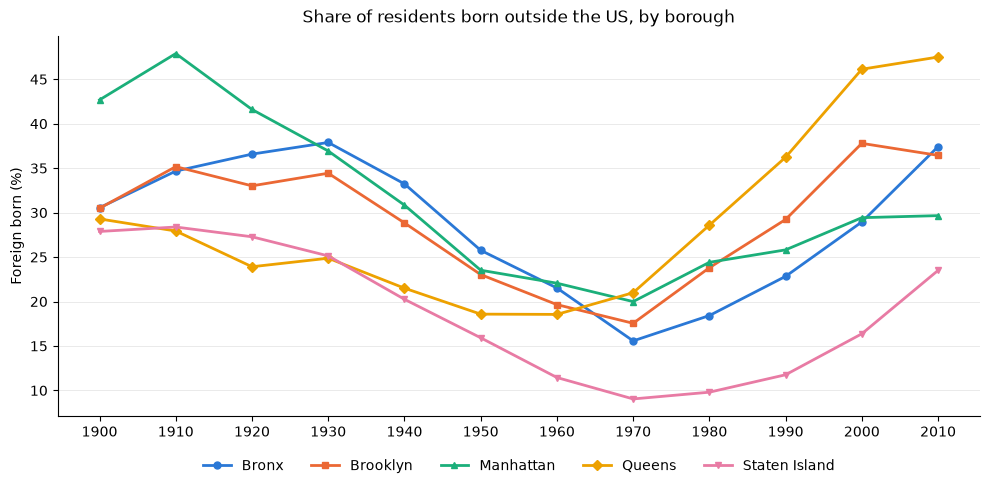

In [16]:
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
markers = ["o", "s", "^", "D", "v"]

fig, ax = plt.subplots(figsize=(10, 5))
for borough, color, marker in zip(foreign.columns, colors, markers):
    ax.plot(foreign.index, foreign[borough], color=color, marker=marker,
            markersize=5, linewidth=2, label=borough)

ax.set_title("Share of residents born outside the US, by borough", fontsize=12, pad=10)
ax.set_ylabel("Foreign born (%)")
ax.set_xticks(foreign.index)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="y", alpha=0.3, linewidth=0.6)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

### Analysis: which borough's makeup shifted most since 1970

Hispanic origin wasn't tracked in 1970, so this uses the four race groups. For each
borough I add up how far each group's share moved between 1970 and 2010 and divide by
two. The result is the share of the population, in percentage points, that is in a
different race group than in 1970.

In [17]:
race = demo[(demo["Category"] == "Race") & demo["Year"].isin([1970, 2010])]
change = race.pivot_table(index=["Borough", "Group"], columns="Year", values="Percent")
change["Change"] = change[2010] - change[1970]
change.round(2)

Year                           1970   2010  Change
Borough       Group                               
Bronx         Asian            0.53   3.68    3.15
              Black           24.30  36.47   12.17
              Other or Mixed   1.72  31.95   30.23
              White           73.44  27.90  -45.54
Brooklyn      Asian            0.62  10.52    9.90
              Black           25.22  34.34    9.12
              Other or Mixed   0.92  12.34   11.42
              White           73.24  42.80  -30.44
Manhattan     Asian            3.08  11.38    8.30
              Black           24.72  15.55   -9.17
              Other or Mixed   1.44  15.62   14.18
              White           70.77  57.45  -13.32
Queens        Asian            1.10  23.01   21.91
              Black           12.99  19.13    6.14
              Other or Mixed   0.57  18.14   17.57
              White           85.34  45.72  -39.62
Staten Island Asian            0.44   7.55    7.11
              Black            5.35  10.64    5.29
              Other or Mixed   0.25   8.92    8.67
              White           93.96  72.89  -21.07

In [18]:
shift = (change["Change"].abs().groupby("Borough").sum() / 2).sort_values(ascending=False)
shift.round(1).rename("Shift (points)")

Borough
Bronx            45.5
Queens           42.6
Brooklyn         30.4
Manhattan        22.5
Staten Island    21.1
Name: Shift (points), dtype: float64

### Conclusions

Every borough follows the same U shape in its foreign-born share. It peaked between
1910 and 1930, fell to its lowest point around 1960 to 1970 after immigration limits,
then climbed back once the 1965 immigration law took effect. Queens changed the most.
It had one of the lowest foreign-born shares in the 1920s and the highest by 2010, at
47.5%. Staten Island has had the lowest share since 1940.

The Bronx shifted most since 1970, at 45.5 points, followed by Queens at 42.6. Most of
the Bronx's shift is in Other or Mixed, which rose from 1.7% to 32.0%. That likely
reflects Hispanic residents choosing "some other race" on the census rather than a
change in who lives there, which shows why the overlapping categories need to stay
labeled.

## Part 2: Library Usage by Branch and Age Group

Joseph's table has two problems at once. The age groups are column headers, and two
different measurements, books borrowed and computer sessions, are stacked in the same
Service Type column.

In [19]:
library = pd.read_csv("library_usage.csv")
library

,Branch,Service Type,Kids (0-12),Teens (13-18),Adults (19-64),Seniors (65+)
0,Downtown,Books Borrowed,520,180,940,610
1,Downtown,Computer Sessions,110,320,580,210
2,Northside,Books Borrowed,340,115,620,450
3,Northside,Computer Sessions,85,210,390,140
4,West End,Books Borrowed,210,90,430,380
5,West End,Computer Sessions,45,160,290,95


### Tidying

`melt()` moves the age groups into rows. `pivot()` then moves books and computer
sessions into their own columns, so each row is one branch and one age group. I also
set the age groups in age order rather than alphabetical order.

In [20]:
long = library.melt(id_vars=["Branch", "Service Type"], var_name="Age Group", value_name="Uses")

usage = (long.pivot(index=["Branch", "Age Group"], columns="Service Type", values="Uses")
             .reset_index())
usage.columns.name = None

age_order = ["Kids (0-12)", "Teens (13-18)", "Adults (19-64)", "Seniors (65+)"]
usage["Age Group"] = pd.Categorical(usage["Age Group"], categories=age_order, ordered=True)
usage["Total"] = usage["Books Borrowed"] + usage["Computer Sessions"]
usage = usage.sort_values(["Branch", "Age Group"]).reset_index(drop=True)
usage

,Branch,Age Group,Books Borrowed,Computer Sessions,Total
0,Downtown,Kids (0-12),520,110,630
1,Downtown,Teens (13-18),180,320,500
2,Downtown,Adults (19-64),940,580,1520
3,Downtown,Seniors (65+),610,210,820
4,Northside,Kids (0-12),340,85,425
5,Northside,Teens (13-18),115,210,325
6,Northside,Adults (19-64),620,390,1010
7,Northside,Seniors (65+),450,140,590
8,West End,Kids (0-12),210,45,255
9,West End,Teens (13-18),90,160,250


### Analysis: books versus computers by age group

In [21]:
by_age = usage.groupby("Age Group", observed=True)[["Books Borrowed", "Computer Sessions"]].sum()
by_age["Computer Share"] = (by_age["Computer Sessions"]
                            / (by_age["Books Borrowed"] + by_age["Computer Sessions"]) * 100).round(1)
by_age

,Books Borrowed,Computer Sessions,Computer Share
Age Group,,,
Kids (0-12),1070,240,18.3
Teens (13-18),385,690,64.2
Adults (19-64),1990,1260,38.8
Seniors (65+),1440,445,23.6


### Analysis: which branches serve the most youth and seniors

Raw totals favor Downtown because it is the busiest branch overall, so I also show each
group's share of the branch's total usage.

In [22]:
usage["Group"] = usage["Age Group"].map({"Kids (0-12)": "Youth", "Teens (13-18)": "Youth",
                                         "Adults (19-64)": "Adults", "Seniors (65+)": "Seniors"})
branch = usage.pivot_table(index="Branch", columns="Group", values="Total", aggfunc="sum")
branch["Youth Share %"] = (branch["Youth"] / branch.sum(axis=1) * 100).round(1)
branch["Senior Share %"] = (branch["Seniors"] / branch[["Adults", "Seniors", "Youth"]].sum(axis=1) * 100).round(1)
branch[["Youth", "Seniors", "Youth Share %", "Senior Share %"]]

Group,Youth,Seniors,Youth Share %,Senior Share %
Branch,,,,
Downtown,1130,820,32.6,23.6
Northside,750,590,31.9,25.1
West End,505,475,29.7,27.9


### Conclusions

Teens are the only group that uses computers more than books, with computer sessions
making up 64.2% of their visits. Kids rely most on physical books, at 18.3% computer
use, followed by seniors at 23.6%. New computers would do the most good in teen spaces.

Downtown serves the most young people by count and by share, at 32.6% of its usage.
West End is the smallest branch but has the highest senior share, 27.9%, which makes it
the best fit for senior programs relative to its size.

## Part 3: NFL Quarterback Passing Stats

Dontae's table packs two variables into each column name: the stat and the season, as
in "Pass Yards 2023". The seasons are spread across columns.

In [23]:
qb = pd.read_csv("qb_stats.csv", thousands=",")
qb

,Quarterback,Pass Yards 2023,Pass Yards 2024,Pass Yards 2025,TDs 2023,TDs 2024,TDs 2025
0,Patrick Mahomes,4183,3928,4587,27,26,30
1,Josh Allen,4306,3731,3668,29,28,25
2,Lamar Jackson,3678,4172,4050,24,41,34


### Tidying

After melting, I split each column name on its last space to separate the stat from
the season. Passing yards and touchdowns are different measurements, so I pivot them
back into their own columns. Each row ends up as one quarterback and one season.

In [24]:
long_qb = qb.melt(id_vars="Quarterback", var_name="Stat Season", value_name="Value")
long_qb[["Stat", "Season"]] = long_qb["Stat Season"].str.rsplit(" ", n=1, expand=True)

seasons = (long_qb.pivot(index=["Quarterback", "Season"], columns="Stat", values="Value")
                  .reset_index())
seasons.columns.name = None
seasons["Season"] = seasons["Season"].astype(int)
seasons

,Quarterback,Season,Pass Yards,TDs
0,Josh Allen,2023,4306,29
1,Josh Allen,2024,3731,28
2,Josh Allen,2025,3668,25
3,Lamar Jackson,2023,3678,24
4,Lamar Jackson,2024,4172,41
5,Lamar Jackson,2025,4050,34
6,Patrick Mahomes,2023,4183,27
7,Patrick Mahomes,2024,3928,26
8,Patrick Mahomes,2025,4587,30


### Analysis: change from season to season

In [25]:
seasons = seasons.sort_values(["Quarterback", "Season"])
seasons[["Yards Change", "TD Change"]] = (seasons.groupby("Quarterback")[["Pass Yards", "TDs"]]
                                                 .diff().astype("Int64"))
seasons

,Quarterback,Season,Pass Yards,TDs,Yards Change,TD Change
0,Josh Allen,2023,4306,29,<NA>,<NA>
1,Josh Allen,2024,3731,28,-575,-1
2,Josh Allen,2025,3668,25,-63,-3
3,Lamar Jackson,2023,3678,24,<NA>,<NA>
4,Lamar Jackson,2024,4172,41,494,17
5,Lamar Jackson,2025,4050,34,-122,-7
6,Patrick Mahomes,2023,4183,27,<NA>,<NA>
7,Patrick Mahomes,2024,3928,26,-255,-1
8,Patrick Mahomes,2025,4587,30,659,4


In [26]:
net = seasons.groupby("Quarterback").agg(Yards_2023=("Pass Yards", "first"), Yards_2025=("Pass Yards", "last"),
                                         TDs_2023=("TDs", "first"), TDs_2025=("TDs", "last"))
net["Yards Change"] = net["Yards_2025"] - net["Yards_2023"]
net["TD Change"] = net["TDs_2025"] - net["TDs_2023"]
net

,Yards_2023,Yards_2025,TDs_2023,TDs_2025,Yards Change,TD Change
Quarterback,,,,,,
Josh Allen,4306,3668,29,25,-638,-4
Lamar Jackson,3678,4050,24,34,372,10
Patrick Mahomes,4183,4587,27,30,404,3


### Conclusions

Josh Allen is the only one who declined in both stats each season, finishing 2025 with
638 fewer yards and 4 fewer touchdowns than in 2023. Lamar Jackson had the biggest
single-season jump, gaining 494 yards and 17 touchdowns in 2024, and kept most of it in
2025 for a net gain of 10 touchdowns. Patrick Mahomes dipped in 2024 and then had his
best season of the three in 2025, with 4,587 yards and 30 touchdowns.